# PrediCare TPA — Entraînement du modèle de fraude 

## M1 : Configuration et chargement

In [1]:
import sys
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sys.path.append("..")
from src.train import (charger_jeu, split_temporel, choisir_seuil, metriques,
                       rappel_par_type, GRAINE)
from src.inference import preparer, REGLES_DURES

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

N_ITER = 20           
RECALL_CIBLE = 0.97   
VERSION = "v2"        
REPORTS = Path("../reports")
MODELS = Path("../models")
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

In [2]:
d = charger_jeu(proc="../data/processed", labels="../data/raw/labels/labels_fraude.csv")
d = d.sort_values("date_soin").reset_index(drop=True)   
tr, va, te = split_temporel(d)

resume = pd.DataFrame({
    "partie": ["train", "validation", "test"],
    "factures": [len(tr), len(va), len(te)],
    "du": [x.date_soin.min().date() for x in (tr, va, te)],
    "au": [x.date_soin.max().date() for x in (tr, va, te)],
    "taux_fraude": [round(x.est_fraude.mean(), 4) for x in (tr, va, te)],
})
display(resume)

,partie,factures,du,au,taux_fraude
0,train,51387,2024-10-01,2025-12-31,0.0879
1,validation,16029,2026-01-01,2026-04-30,0.0841
2,test,17177,2026-05-01,2026-10-01,0.0863


## M2 : Préparation des matrices

In [3]:
COLONNES = [c for c in d.columns
            if c not in ("facture_id", "date_soin", "est_fraude", "type_fraude")]
CATEGORIES = {c: list(d[c].cat.categories) for c in COLONNES if str(d[c].dtype) == "category"}


def prep(df):
    return preparer(df[COLONNES], CATEGORIES, COLONNES)


Xtr, Xva, Xte = prep(tr), prep(va), prep(te)
ytr, yva, yte = tr.est_fraude.values, va.est_fraude.values, te.est_fraude.values

spw = (ytr == 0).sum() / (ytr == 1).sum()
print(len(COLONNES), "variables | scale_pos_weight =", round(spw, 2))

66 variables | scale_pos_weight = 10.38


## M3 : Traitement du déséquilibre



In [4]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, precision_score


def essai(nom, X, y, Xv, **kw):
    m = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method="hist",
                      random_state=GRAINE, n_jobs=-1, **kw)
    m.fit(X, y)
    p = m.predict_proba(Xv)[:, 1]
    s = choisir_seuil(yva, p, RECALL_CIBLE)
    return {"méthode": nom, "pr_auc_validation": round(average_precision_score(yva, p), 4),
            "seuil": round(s, 3),
            "precision_au_rappel_cible": round(precision_score(yva, p >= s), 4)}


resultats = [essai("aucune", Xtr, ytr, Xva, enable_categorical=True),
             essai("scale_pos_weight", Xtr, ytr, Xva, enable_categorical=True,
                   scale_pos_weight=spw)]

# SMOTENC : demande des catégories encodées en nombres et sans valeurs manquantes
try:
    from imblearn.over_sampling import SMOTENC

    def encoder(X):
        Z = X.copy()
        for c in CATEGORIES:
            Z[c] = Z[c].cat.codes
        return Z.fillna(-1).astype(float)

    idx_cat = [COLONNES.index(c) for c in CATEGORIES]
    Xs, ys = SMOTENC(categorical_features=idx_cat, random_state=GRAINE).fit_resample(encoder(Xtr), ytr)
    resultats.append(essai("SMOTENC", Xs, ys, encoder(Xva)))
except ImportError:
    print("imbalanced-learn absent : pip install imbalanced-learn pour tester SMOTENC")

comparaison_desequilibre = pd.DataFrame(resultats)
display(comparaison_desequilibre)

,méthode,pr_auc_validation,seuil,precision_au_rappel_cible
0,aucune,0.9922,0.235,0.9350
1,scale_pos_weight,0.9911,0.570,0.9336
2,SMOTENC,0.9922,0.260,0.9363


## M4 : Recherche d'hyperparamètres — XGBoost



In [ ]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

espace = {
    "n_estimators": [200, 400, 600, 800],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.02, 0.05, 0.08, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.3, 0.5],
}

recherche = RandomizedSearchCV(
    estimator=XGBClassifier(tree_method="hist", enable_categorical=True,
                            scale_pos_weight=spw, eval_metric="aucpr",
                            random_state=GRAINE, n_jobs=-1),
    param_distributions=espace,
    n_iter=N_ITER,
    scoring={"pr_auc": "average_precision", "rappel": "recall"},
    refit="pr_auc",
    cv=TimeSeriesSplit(n_splits=4),
    random_state=GRAINE,
    n_jobs=1,            
    verbose=1,
)
recherche.fit(Xtr, ytr)

print("Meilleurs hyperparamètres :")
print(json.dumps({k: (v.item() if hasattr(v, "item") else v)
                  for k, v in recherche.best_params_.items()}, indent=2))
print("PR-AUC moyenne en validation croisée :", round(recherche.best_score_, 4))

Fitting 4 folds for each of 20 candidates, totalling 80 fits


,mean_test_pr_auc,std_test_pr_auc,mean_test_rappel,params
0,0.9860,0.0035,0.9620,"{'subsample': 1.0, 'n_estimators': 800, 'min_c..."
1,0.9859,0.0032,0.9603,"{'subsample': 1.0, 'n_estimators': 800, 'min_c..."
2,0.9858,0.0028,0.9657,"{'subsample': 1.0, 'n_estimators': 200, 'min_c..."
3,0.9856,0.0031,0.9581,"{'subsample': 1.0, 'n_estimators': 600, 'min_c..."
4,0.9854,0.0046,0.9544,"{'subsample': 0.8, 'n_estimators': 600, 'min_c..."
5,0.9853,0.0040,0.9544,"{'subsample': 0.8, 'n_estimators': 800, 'min_c..."
6,0.9846,0.0037,0.9566,"{'subsample': 0.8, 'n_estimators': 800, 'min_c..."
7,0.9846,0.0045,0.9538,"{'subsample': 0.8, 'n_estimators': 800, 'min_c..."
8,0.9845,0.0035,0.9620,"{'subsample': 0.8, 'n_estimators': 600, 'min_c..."
9,0.9841,0.0048,0.9626,"{'subsample': 0.8, 'n_estimators': 200, 'min_c..."


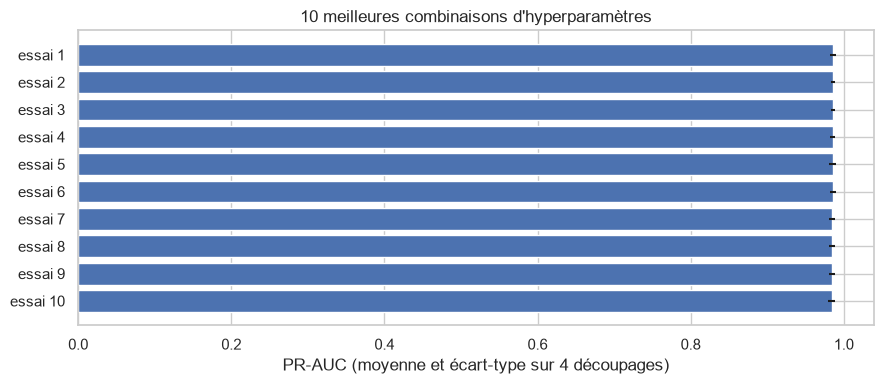

In [ ]:
res = (pd.DataFrame(recherche.cv_results_)
       [["mean_test_pr_auc", "std_test_pr_auc", "mean_test_rappel", "params"]]
       .sort_values("mean_test_pr_auc", ascending=False).reset_index(drop=True))
display(res.head(10).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
top = res.head(10)
ax.barh(range(len(top)), top.mean_test_pr_auc[::-1], xerr=top.std_test_pr_auc[::-1])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"essai {i + 1}" for i in range(len(top))][::-1])
ax.set_xlabel("PR-AUC (moyenne et écart-type sur 4 découpages)")
ax.set_title("10 meilleures combinaisons d'hyperparamètres")
plt.tight_layout()
plt.savefig(REPORTS / "hyperparametres_top10.png", dpi=120)
plt.show()

## M5 : Entraînement final et choix du seuil



In [ ]:
params = dict(recherche.best_params_)
modele = XGBClassifier(**params, tree_method="hist", enable_categorical=True,
                       scale_pos_weight=spw, eval_metric="aucpr",
                       early_stopping_rounds=30, random_state=GRAINE, n_jobs=-1)
modele.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)

p_va = modele.predict_proba(Xva)[:, 1]
p_te = modele.predict_proba(Xte)[:, 1]
print("Arbres retenus par l'arrêt anticipé :", modele.best_iteration + 1)

Arbres retenus par l'arrêt anticipé : 358


Seuil retenu (validation, rappel cible 0.97) : 0.7287


,rappel,precision,taux_alerte
seuil,,,
0.100,0.9926,0.7197,0.1160
0.300,0.9889,0.9162,0.0908
0.500,0.9815,0.9356,0.0882
0.700,0.9718,0.9555,0.0855
0.729,0.9696,0.9582,0.0851
0.800,0.9547,0.9721,0.0826
0.900,0.9258,0.9913,0.0785


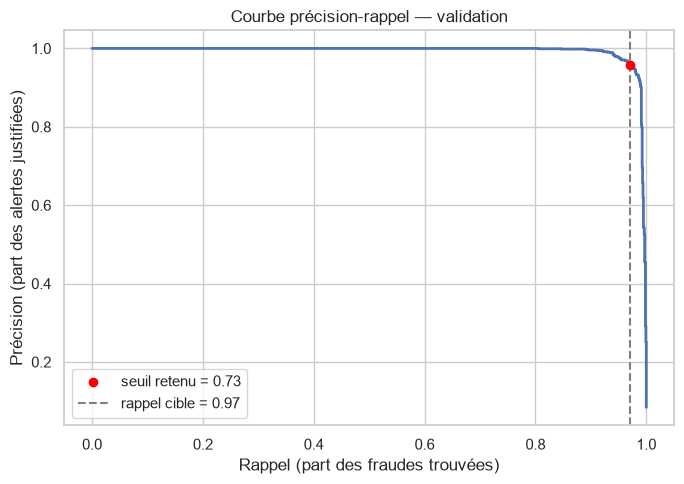

In [ ]:
from sklearn.metrics import precision_recall_curve

seuil = choisir_seuil(yva, p_va, RECALL_CIBLE)
print(f"Seuil retenu (validation, rappel cible {RECALL_CIBLE}) : {seuil:.4f}")

lignes = []
for s in [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, round(seuil, 3)]:
    m = metriques(yva, p_va, s)
    lignes.append({"seuil": s, "rappel": m["rappel"], "precision": m["precision"],
                   "taux_alerte": m["taux_alerte"]})
display(pd.DataFrame(lignes).sort_values("seuil").set_index("seuil"))

prec, rap, seuils = precision_recall_curve(yva, p_va)
plt.figure(figsize=(7, 5))
plt.plot(rap, prec, lw=2)
plt.scatter([metriques(yva, p_va, seuil)["rappel"]], [metriques(yva, p_va, seuil)["precision"]],
            color="red", zorder=5, label=f"seuil retenu = {seuil:.2f}")
plt.axvline(RECALL_CIBLE, color="gray", linestyle="--", label=f"rappel cible = {RECALL_CIBLE}")
plt.xlabel("Rappel (part des fraudes trouvées)")
plt.ylabel("Précision (part des alertes justifiées)")
plt.title("Courbe précision-rappel — validation")
plt.legend()
plt.tight_layout()
plt.savefig(REPORTS / "precision_rappel_validation.png", dpi=120)
plt.show()

## M6 : Évaluation sur le test 



In [ ]:
res_test = metriques(yte, p_te, seuil)
res_val = metriques(yva, p_va, seuil)
display(pd.DataFrame({"validation": res_val, "test": res_test}))

,validation,test
seuil,0.7287,0.7287
rappel,0.9703,0.9487
precision,0.9582,0.9717
taux_alerte,0.0852,0.0842
pr_auc,0.9935,0.9897
roc_auc,0.9989,0.9973


### Matrice de confusion

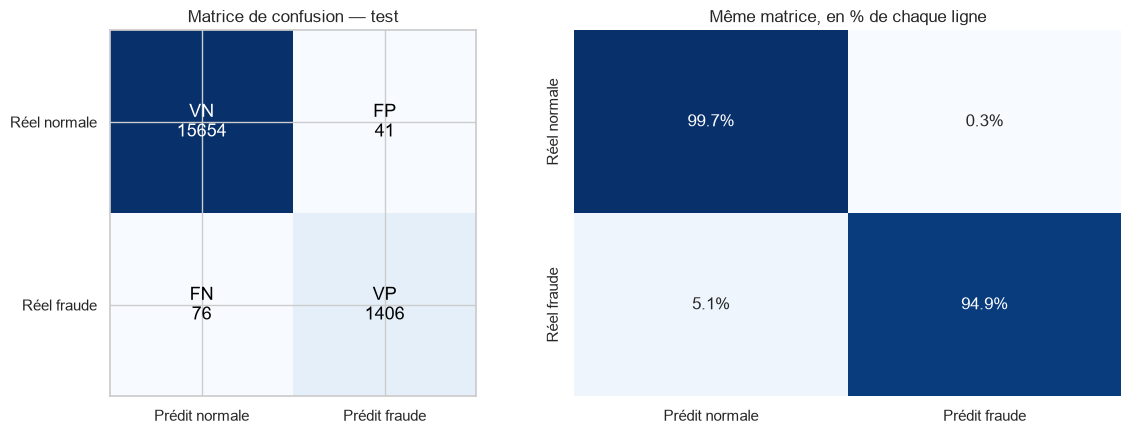

Fraudes détectées (VP)      : 1406
Fraudes manquées (FN)       : 76   <- le coût à minimiser
Fausses alertes (FP)        : 41   <- du travail inutile pour les gestionnaires


In [ ]:
from sklearn.metrics import confusion_matrix

pred = (p_te >= seuil).astype(int)
cm = confusion_matrix(yte, pred)
tn, fp, fn, tp = cm.ravel()
cm_values = [[tn, fp], [fn, tp]]
cm_labels = [["VN", "FP"], ["FN", "VP"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].imshow(cm_values, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Prédit normale", "Prédit fraude"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["Réel normale", "Réel fraude"])
axes[0].set_title("Matrice de confusion — test")
vmax = max(max(r) for r in cm_values) or 1
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm_labels[i][j]}\n{cm_values[i][j]}", ha="center", va="center",
                     color="white" if cm_values[i][j] > vmax / 2 else "black", fontsize=13)

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Prédit normale", "Prédit fraude"],
            yticklabels=["Réel normale", "Réel fraude"])
axes[1].set_title("Même matrice, en % de chaque ligne")
plt.tight_layout()
plt.savefig(REPORTS / "matrice_confusion_test.png", dpi=120)
plt.show()

print(f"Fraudes détectées (VP)      : {tp}")
print(f"Fraudes manquées (FN)       : {fn}   <- le coût à minimiser")
print(f"Fausses alertes (FP)        : {fp}   <- du travail inutile pour les gestionnaires")

### Courbes ROC et précision-rappel

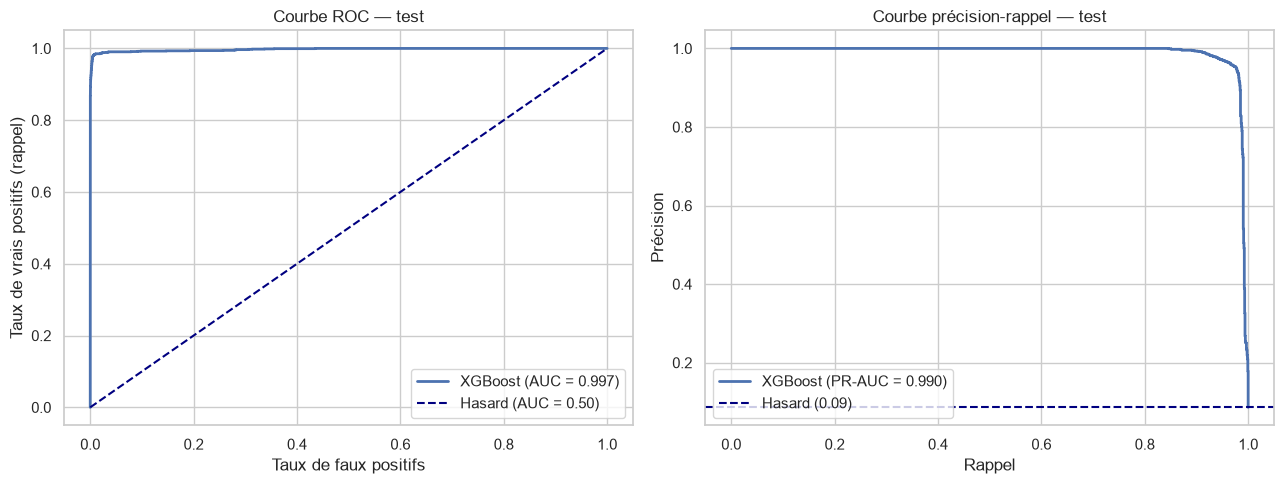

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fpr, tpr, _ = roc_curve(yte, p_te)
axes[0].plot(fpr, tpr, lw=2, label=f"XGBoost (AUC = {roc_auc_score(yte, p_te):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="navy", label="Hasard (AUC = 0.50)")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title("Courbe ROC — test")
axes[0].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(yte, p_te)
axes[1].plot(rc, pr, lw=2, label=f"XGBoost (PR-AUC = {average_precision_score(yte, p_te):.3f})")
axes[1].axhline(yte.mean(), linestyle="--", color="navy", label=f"Hasard ({yte.mean():.2f})")
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbe précision-rappel — test")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.savefig(REPORTS / "courbes_roc_pr_test.png", dpi=120)
plt.show()

### Rappel par type de fraude

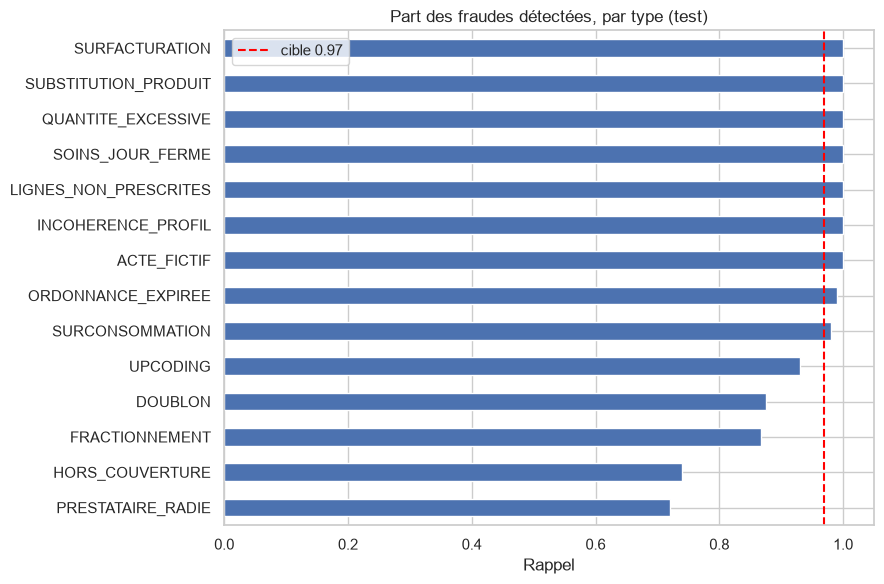

,rappel,nb_fraudes_test
PRESTATAIRE_RADIE,0.720,100
HORS_COUVERTURE,0.739,23
FRACTIONNEMENT,0.867,60
DOUBLON,0.876,178
UPCODING,0.931,144
SURCONSOMMATION,0.980,49
ORDONNANCE_EXPIREE,0.991,110
ACTE_FICTIF,1.000,88
INCOHERENCE_PROFIL,1.000,69
LIGNES_NON_PRESCRITES,1.000,159


In [ ]:
rpt = pd.Series(rappel_par_type(te, p_te, seuil)).sort_values()
n_par_type = te[te.est_fraude == 1].type_fraude.value_counts()

fig, ax = plt.subplots(figsize=(9, 6))
rpt.plot.barh(ax=ax)
ax.axvline(RECALL_CIBLE, color="red", linestyle="--", label=f"cible {RECALL_CIBLE}")
ax.set_xlim(0, 1.05)
ax.set_xlabel("Rappel")
ax.set_title("Part des fraudes détectées, par type (test)")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "rappel_par_type.png", dpi=120)
plt.show()

display(pd.DataFrame({"rappel": rpt, "nb_fraudes_test": n_par_type.reindex(rpt.index)}))

### Modèle seul ou modèle + règles dures



In [ ]:
dures = [c for c in REGLES_DURES if c in te.columns]
h = te[dures].fillna(False).astype(bool).any(axis=1).values
a_modele = p_te >= seuil
a_hybride = a_modele | h

lignes = []
for nom, a in [("modèle seul", a_modele), ("modèle OU règles dures", a_hybride)]:
    lignes.append({"stratégie": nom,
                   "rappel": round(((a) & (yte == 1)).sum() / (yte == 1).sum(), 4),
                   "precision": round(((a) & (yte == 1)).sum() / a.sum(), 4),
                   "taux_alerte": round(a.mean(), 4)})
display(pd.DataFrame(lignes).set_index("stratégie"))

,rappel,precision,taux_alerte
stratégie,,,
modèle seul,0.9487,0.9717,0.0842
modèle OU règles dures,0.9723,0.9665,0.0868


## M7 : Quelles variables contribuent à la décision ?



,gain
nb_signaux,2170.39
validite_jours,438.94
ord_type,312.38
est_copie,193.53
type_facture,181.30
nb_meme_jour,128.70
nb_fact_ord,124.71
niveau_tarif,98.80
heure_fermeture,98.60
nb_meme_numero,87.17


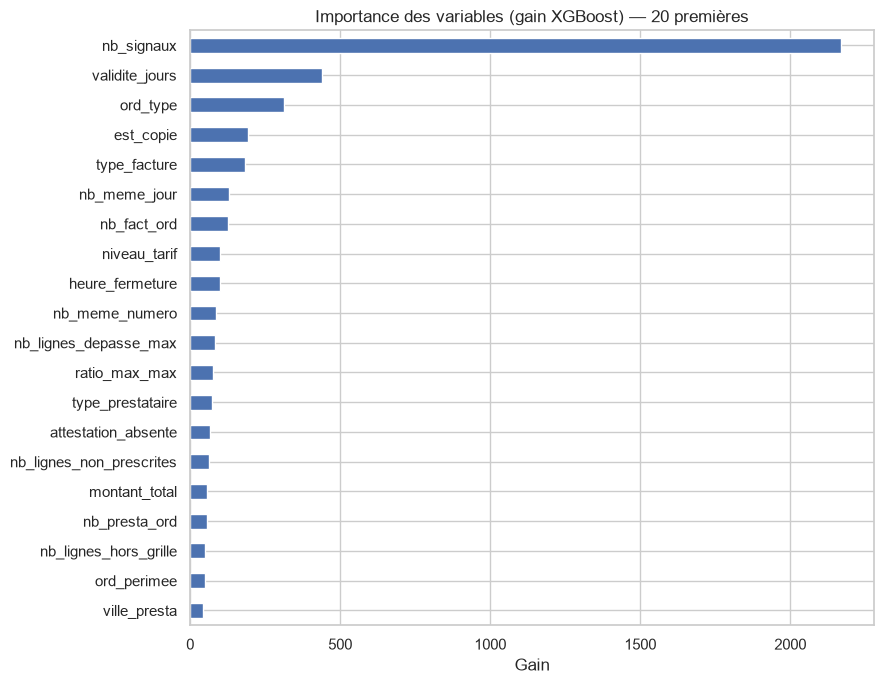

In [ ]:
imp = (pd.Series(modele.get_booster().get_score(importance_type="gain"))
       .sort_values(ascending=False))
display(imp.head(20).round(2).to_frame("gain"))

fig, ax = plt.subplots(figsize=(9, 7))
imp.head(20)[::-1].plot.barh(ax=ax)
ax.set_title("Importance des variables (gain XGBoost) — 20 premières")
ax.set_xlabel("Gain")
plt.tight_layout()
plt.savefig(REPORTS / "importance_gain.png", dpi=120)
plt.show()

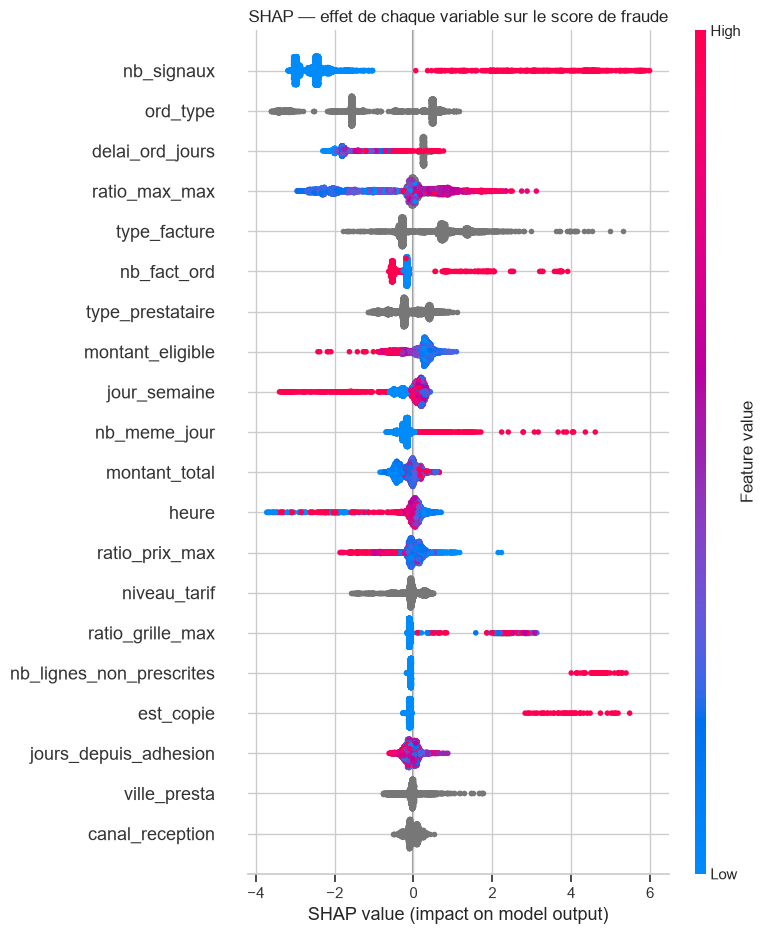

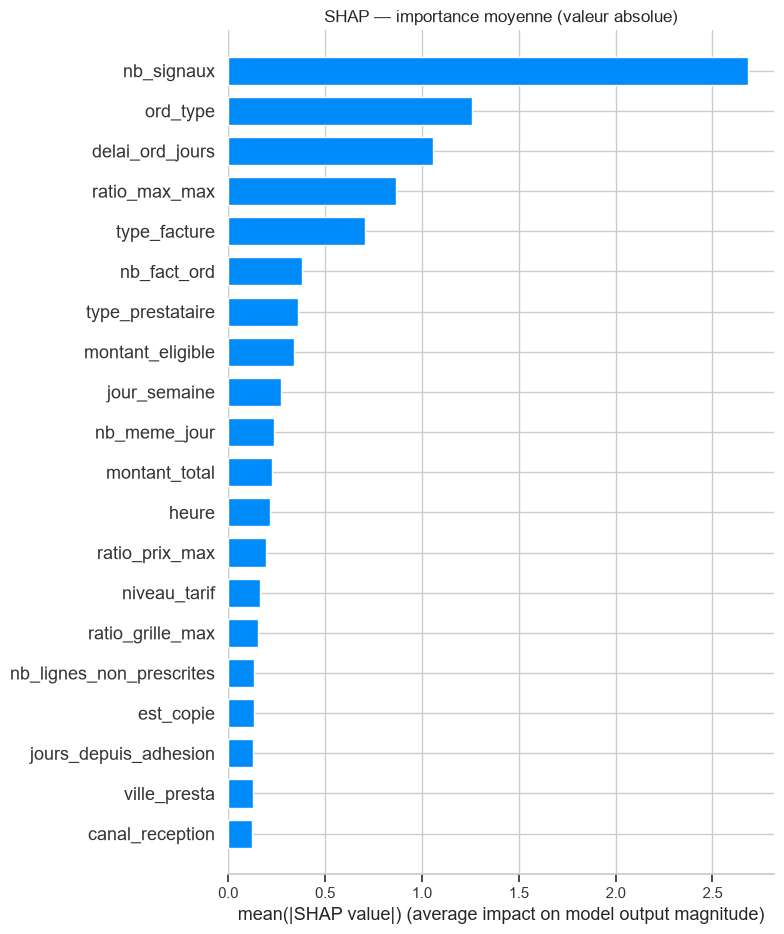

,|SHAP| moyen
nb_signaux,2.6833
ord_type,1.2582
delai_ord_jours,1.0568
ratio_max_max,0.8651
type_facture,0.7059
nb_fact_ord,0.3787
type_prestataire,0.3603
montant_eligible,0.3401
jour_semaine,0.2704
nb_meme_jour,0.2370


In [ ]:
import shap

echant = Xte.sample(min(5000, len(Xte)), random_state=GRAINE)
explainer = shap.TreeExplainer(modele)
sv = explainer.shap_values(echant)
sv = sv[1] if isinstance(sv, list) else sv

shap.summary_plot(sv, echant, max_display=20, show=False)
plt.title("SHAP — effet de chaque variable sur le score de fraude")
plt.tight_layout()
plt.savefig(REPORTS / "shap_beeswarm.png", dpi=120)
plt.show()

shap.summary_plot(sv, echant, plot_type="bar", max_display=20, show=False)
plt.title("SHAP — importance moyenne (valeur absolue)")
plt.tight_layout()
plt.savefig(REPORTS / "shap_bar.png", dpi=120)
plt.show()

importance_shap = (pd.Series(np.abs(sv).mean(axis=0), index=echant.columns)
                   .sort_values(ascending=False))
display(importance_shap.head(15).round(4).to_frame("|SHAP| moyen"))

### Une facture expliquée en détail

Facture : FAC-00013148 | type de fraude réel : SURFACTURATION | score : 0.9999


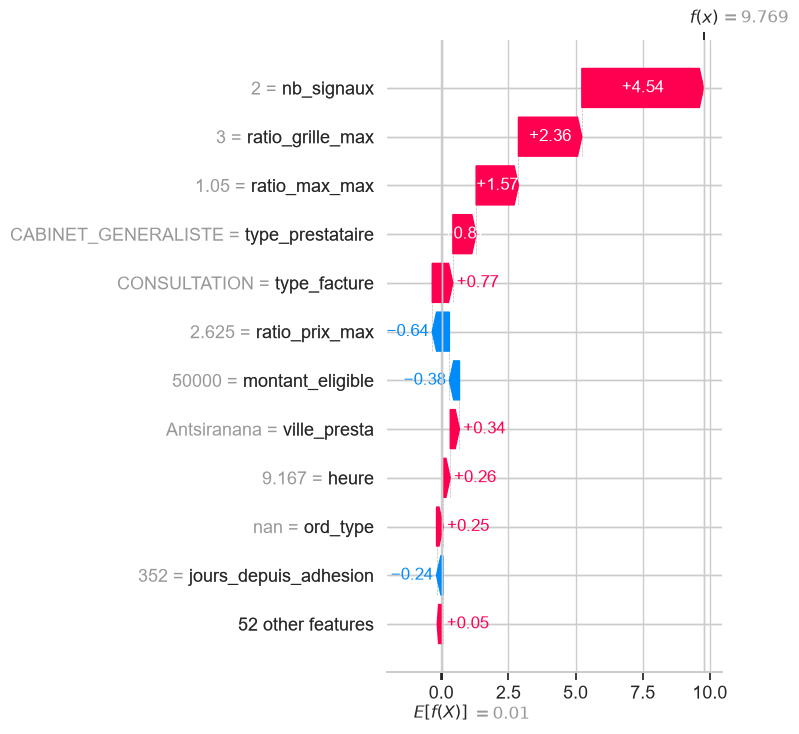

In [ ]:
i = int(np.where((p_te >= seuil) & (yte == 1))[0][0])   # première fraude correctement détectée
base = explainer.expected_value
base = float(base[0]) if hasattr(base, "__len__") else float(base)
vals = explainer.shap_values(Xte.iloc[[i]])
vals = vals[1] if isinstance(vals, list) else vals
expl = shap.Explanation(values=vals[0], base_values=base,
                        data=Xte.iloc[i].values, feature_names=list(Xte.columns))
print("Facture :", te.iloc[i].facture_id, "| type de fraude réel :", te.iloc[i].type_fraude,
      "| score :", round(float(p_te[i]), 4))
shap.plots.waterfall(expl, max_display=12, show=False)
plt.tight_layout()
plt.savefig(REPORTS / "shap_une_facture.png", dpi=120, bbox_inches="tight")
plt.show()

## M8 : Comparaison avec le modèle de référence



In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

ref = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, class_weight="balanced",
                                     categorical_features="from_dtype", random_state=GRAINE)
ref.fit(Xtr, ytr)
pr_va, pr_te = ref.predict_proba(Xva)[:, 1], ref.predict_proba(Xte)[:, 1]
seuil_ref = choisir_seuil(yva, pr_va, RECALL_CIBLE)

comparaison = pd.DataFrame({
    "baseline (HGB)": metriques(yte, pr_te, seuil_ref),
    "XGBoost optimisé": metriques(yte, p_te, seuil),
})
display(comparaison)

,baseline (HGB),XGBoost optimisé
seuil,0.7213,0.7287
rappel,0.9622,0.9487
precision,0.9721,0.9717
taux_alerte,0.0854,0.0842
pr_auc,0.9918,0.9897
roc_auc,0.9981,0.9973


## M9 : Sauvegarde de la version



In [ ]:
import joblib

dossier = MODELS / VERSION
dossier.mkdir(parents=True, exist_ok=True)
joblib.dump(modele, dossier / "model.joblib")

meta = {
    "version": VERSION,
    "modele": "xgb",
    "date": datetime.now().isoformat(timespec="seconds"),
    "colonnes": COLONNES,
    "categories": CATEGORIES,
    "seuil": float(seuil),
    "recall_cible": RECALL_CIBLE,
    "scale_pos_weight": float(spw),
    "hyperparametres": {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()},
    "split": {"train": len(tr), "validation": len(va), "test": len(te)},
    "resultats": {"validation": res_val, "test": res_test,
                  "rappel_par_type_test": rappel_par_type(te, p_te, seuil)},
}
(dossier / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False),
                                       encoding="utf-8")
print("Version sauvegardée dans", dossier.resolve())

Version sauvegardée dans E:\predicare\models\v2


In [ ]:
# Vérification : la version sauvegardée fonctionne via la fonction de prédiction de l'API
from src.inference import predire

echantillon = te.drop(columns=["date_soin", "est_fraude", "type_fraude"]).head(1000)
sortie = predire(echantillon, VERSION, models_dir=MODELS)
display(sortie.head())
print("Scores identiques au notebook :",
      bool(np.allclose(sortie.score.values, p_te[:1000], atol=1e-6)))

,facture_id,score,regle_dure,a_controler,alerte,version_modele
0,FAC-00032069,0.017973,False,False,False,v2
1,FAC-00008659,0.000376,False,False,False,v2
2,FAC-00029457,0.001003,False,False,False,v2
3,FAC-00055363,0.118773,False,False,False,v2
4,FAC-00055615,0.016122,False,False,False,v2


Scores identiques au notebook : True


In [ ]:
#  Enregistrer l'essai dans MLflow pour le comparer aux autres versions
try:
    import mlflow
    mlflow.set_experiment("predicare-fraude")
    with mlflow.start_run(run_name=f"notebook-xgb-{VERSION}"):
        mlflow.log_params(meta["hyperparametres"])
        mlflow.log_params({"recall_cible": RECALL_CIBLE, "seuil": round(float(seuil), 4)})
        for k, v in res_test.items():
            mlflow.log_metric(f"test_{k}", v)
        mlflow.log_artifact(str(dossier / "metadata.json"))
    print("Run MLflow enregistrée")
except ImportError:
    print("MLflow non installé : étape ignorée")

Run MLflow enregistrée
